In [1]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

# Find project root from the current working directory
root = Path.cwd()
if not (root / "data").exists():
    root = root.parent

data_path = (
    root / "data" / "processed"
    / "de_lu_hourly_prices_2023_2025.parquet"
)

df = pd.read_parquet(data_path)

print("Dataset shape:", df.shape)
print("\nFirst five rows:")
display(df.head())

print("\nData types:")
print(df.dtypes)

print("\nSummary statistics:")
display(df.describe())


Dataset shape: (26304, 1)

First five rows:


,price_eur_mwh
timestamp_utc,
2022-12-31 23:00:00+00:00,-5.17
2023-01-01 00:00:00+00:00,-1.07
2023-01-01 01:00:00+00:00,-1.47
2023-01-01 02:00:00+00:00,-5.08
2023-01-01 03:00:00+00:00,-4.49



Data types:
price_eur_mwh    float64
dtype: object

Summary statistics:


,price_eur_mwh
count,26304.000000
mean,87.661380
std,51.322103
min,-500.000000
25%,65.060000
50%,90.060000
75%,112.970000
max,936.280000


Create useful time features for analysis.

In [4]:

# Convert UTC timestamps to German market time
df["timestamp_local"] = df.index.tz_convert("Europe/Berlin")

df["year"] = df["timestamp_local"].dt.year
df["month"] = df["timestamp_local"].dt.month
df["hour"] = df["timestamp_local"].dt.hour
df["day_of_week"] = df["timestamp_local"].dt.day_of_week

print("Years:", df["year"].unique())
print("Total observations:", len(df))
print("Negative-price hours:", (df["price_eur_mwh"] < 0).sum())

display(df.head())


Years: [2023 2024 2025]
Total observations: 26304
Negative-price hours: 1334


,price_eur_mwh,timestamp_local,year,month,hour,day_of_week
timestamp_utc,,,,,,
2022-12-31 23:00:00+00:00,-5.17,2023-01-01 00:00:00+01:00,2023,1,0,6
2023-01-01 00:00:00+00:00,-1.07,2023-01-01 01:00:00+01:00,2023,1,1,6
2023-01-01 01:00:00+00:00,-1.47,2023-01-01 02:00:00+01:00,2023,1,2,6
2023-01-01 02:00:00+00:00,-5.08,2023-01-01 03:00:00+01:00,2023,1,3,6
2023-01-01 03:00:00+00:00,-4.49,2023-01-01 04:00:00+01:00,2023,1,4,6


Visualize the historical electricity price trend.

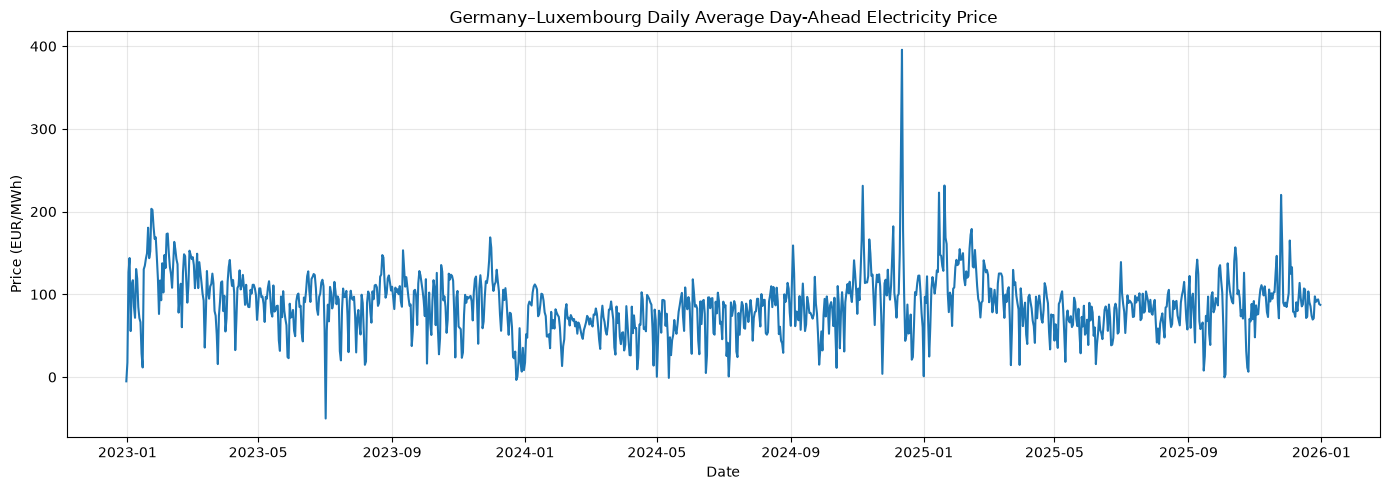

In [5]:

daily_prices = df["price_eur_mwh"].resample("D").mean()

plt.figure(figsize=(14, 5))
plt.plot(daily_prices.index, daily_prices.values)

plt.title("Germany–Luxembourg Daily Average Day-Ahead Electricity Price")
plt.xlabel("Date")
plt.ylabel("Price (EUR/MWh)")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


Start with monthly and hourly price analysis
1. Monthly price trends: Identify seasonal patterns across 2023–2025.
2. Hourly price patterns: Determine which hours have the highest and lowest average prices.

Compare the monthly price patterns of 2023, 2024, and 2025.

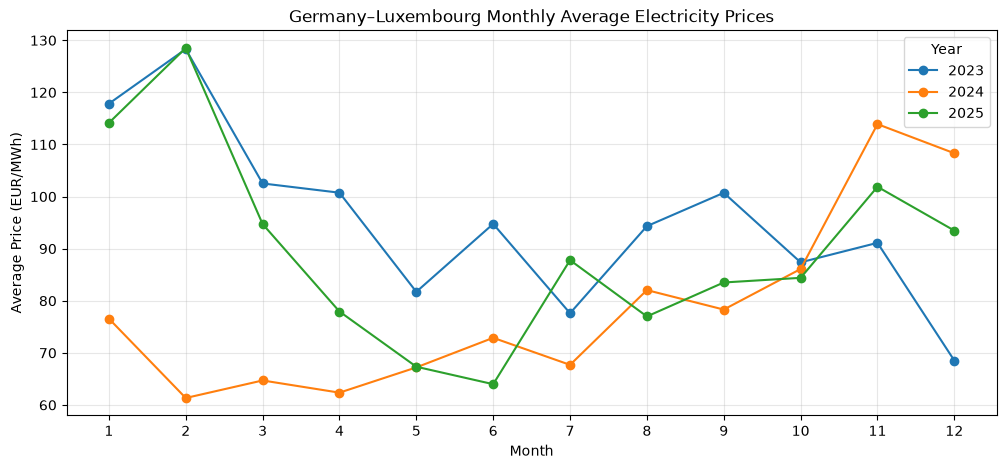

In [6]:
import matplotlib.pyplot as plt

# Monthly average electricity prices
monthly = df.groupby(
    ["year", "month"]
)["price_eur_mwh"].mean().unstack(0)

monthly.plot(figsize=(12, 5), marker="o")

plt.title("Germany–Luxembourg Monthly Average Electricity Prices")
plt.xlabel("Month")
plt.ylabel("Average Price (EUR/MWh)")
plt.xticks(range(1, 13))
plt.grid(alpha=0.3)
plt.legend(title="Year")
plt.show()

2023: Electricity prices were particularly high in January–February, reaching approximately €128/MWh in February. 
   
2024: Prices were comparatively low during the first half of the year, but increased sharply toward November and December.  
  
2025: Prices peaked in February, declined through June, and increased again toward the end of the year.  
  

Seasonality: Winter months often show higher prices, although the pattern is not consistent across every year.

## Hourly Price Analysis

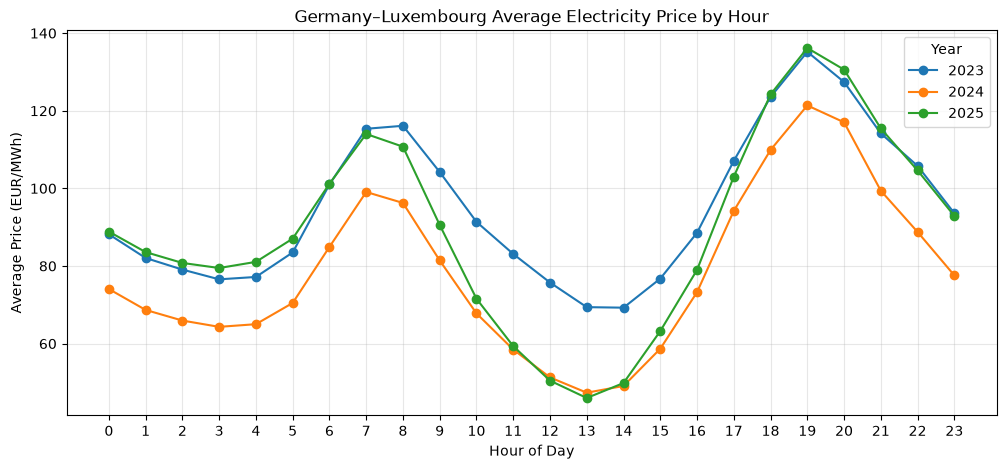

In [7]:
hourly = df.groupby(
    ["year", "hour"]
)["price_eur_mwh"].mean().unstack(0)

hourly.plot(figsize=(12, 5), marker="o")

plt.title("Germany–Luxembourg Average Electricity Price by Hour")
plt.xlabel("Hour of Day")
plt.ylabel("Average Price (EUR/MWh)")
plt.xticks(range(24))
plt.grid(alpha=0.3)
plt.legend(title="Year")
plt.show()

Lowest prices: Around 13:00 across all three years, approximately €46–69/MWh.



Highest prices: Around 19:00, reaching approximately €135/MWh in 2025.



2024: Generally cheaper than 2023 and 2025 throughout most of the day.



2025: Stronger evening price peaks compared with 2024.

## Negative electricity price analysis
The dataset showed 1,334 negative-price hours, representing approximately 5.07% of all observations.

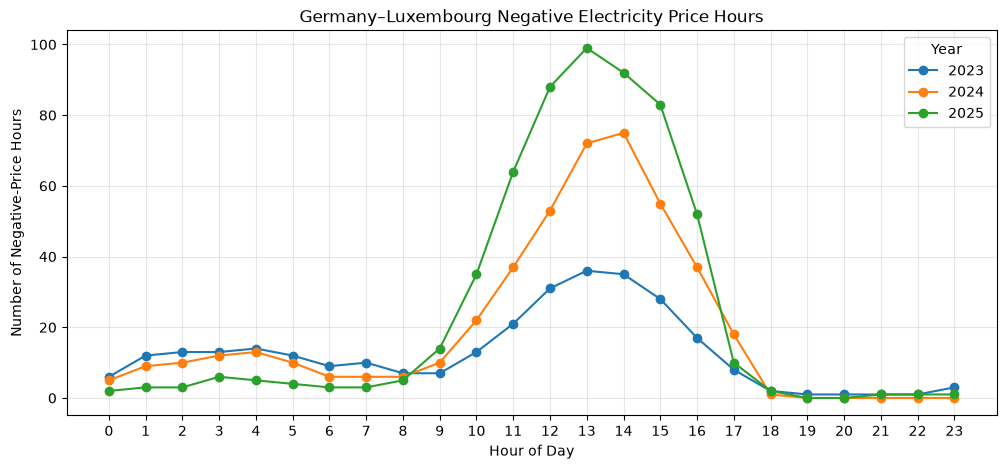

Negative-price hours by year:
year
2023    301
2024    457
2025    576
dtype: int64


In [8]:
# Filter negative electricity prices
negative = df[df["price_eur_mwh"] < 0].copy()

# Count negative-price hours by hour and year
negative_hourly = negative.groupby(
    ["year", "hour"]
).size().unstack(0, fill_value=0)

negative_hourly.plot(
    figsize=(12, 5),
    marker="o"
)

plt.title("Germany–Luxembourg Negative Electricity Price Hours")
plt.xlabel("Hour of Day")
plt.ylabel("Number of Negative-Price Hours")
plt.xticks(range(24))
plt.grid(alpha=0.3)
plt.legend(title="Year")
plt.show()

# Count by year
print("Negative-price hours by year:")
print(negative.groupby("year").size())

Negative electricity prices are increasingly concentrated around midday, and their frequency has risen substantially from 2023 to 2025.

2023: Negative prices occurred less frequently and were more evenly distributed across daytime and overnight hours.



2024: A noticeable increase in negative-price occurrences around midday.



2025: Negative prices became even more frequent, particularly between 11:00 and 15:00.

## Price volatility analysis

Measure how much electricity prices fluctuate within each year.

In [10]:
# Annual electricity price statistics
volatility = df.groupby("year")["price_eur_mwh"].agg(
    ["mean", "std", "min", "max"]
)

volatility["price_range"] = (
    volatility["max"] - volatility["min"]
)

print(volatility.round(2))

       mean    std     min     max  price_range
year                                           
2023  95.18  47.58 -500.00  524.27      1024.27
2024  78.51  52.73 -135.45  936.28      1071.73
2025  89.32  52.10 -250.32  583.40       833.72


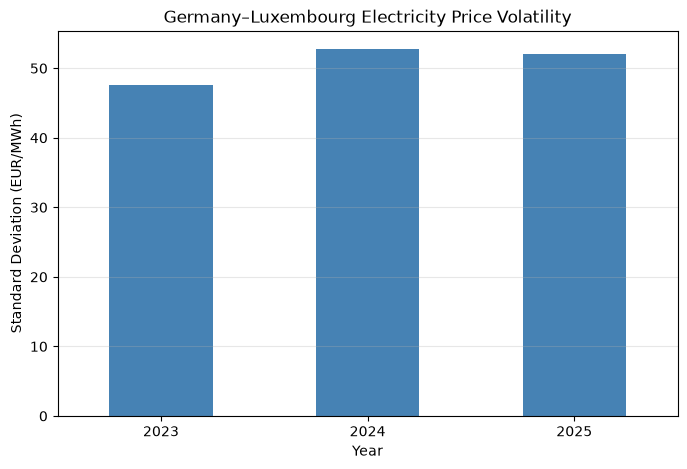

In [11]:
volatility["std"].plot(
    kind="bar",
    figsize=(8, 5),
    color="steelblue"
)

plt.title("Germany–Luxembourg Electricity Price Volatility")
plt.xlabel("Year")
plt.ylabel("Standard Deviation (EUR/MWh)")
plt.xticks(rotation=0)
plt.grid(axis="y", alpha=0.3)
plt.show()

Key findings
- 2024 was the most volatile year, with the highest standard deviation (€52.73/MWh).
- 2023 had the highest average price, at €95.18/MWh.
- 2024 had the lowest average price, despite experiencing the highest hourly price spike.
- 2025 remained highly volatile, with a standard deviation close to 2024.
An important finding is that lower average electricity prices do not necessarily mean a more stable electricity market.

## Hour-to-hour price changes

Helps detect sudden price movements

In [12]:
# Sort observations chronologically
df = df.sort_index().copy()

# Calculate hourly price changes
df["price_change"] = df["price_eur_mwh"].diff()

# Absolute price changes
df["abs_price_change"] = df["price_change"].abs()

# Annual statistics
hourly_changes = df.groupby("year")["abs_price_change"].agg(
    ["mean", "median", "max"]
)

print(hourly_changes.round(2))

       mean  median     max
year                       
2023  10.81    7.19  274.79
2024  11.90    7.08  423.81
2025  13.23    7.64  241.65


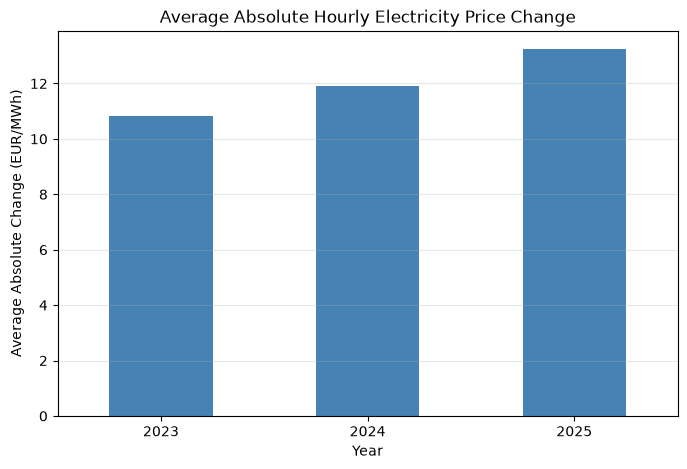

In [14]:
hourly_changes["mean"].plot(
    kind="bar",
    figsize=(8, 5),
    color="steelblue"
)

plt.title("Average Absolute Hourly Electricity Price Change")
plt.xlabel("Year")
plt.ylabel("Average Absolute Change (EUR/MWh)")
plt.xticks(rotation=0)
plt.grid(axis="y", alpha=0.3)
plt.show()

## Anomaly detection

Identify unusually large hourly price movements.  
We use simple statistical method using the 99th percentile of absolute hourly price changes.
This flags the largest 1% of hourly price movements across the dataset. These are statistical anomalies, not necessarily errors or abnormal market behavior.

In [15]:
# Calculate anomaly threshold
threshold = df["abs_price_change"].quantile(0.99)

# Flag unusually large hourly movements
df["is_anomaly"] = (
    df["abs_price_change"] > threshold
)

print(f"Anomaly threshold: €{threshold:.2f}/MWh")

print("\nAnomalies by year:")
print(df.groupby("year")["is_anomaly"].sum())

print("\nTop 10 largest hourly movements:")
print(
    df.nlargest(10, "abs_price_change")[
        ["price_eur_mwh", "price_change", "abs_price_change"]
    ]
)

Anomaly threshold: €71.04/MWh

Anomalies by year:
year
2023     49
2024     89
2025    126
Name: is_anomaly, dtype: int64

Top 10 largest hourly movements:
                           price_eur_mwh  price_change  abs_price_change
timestamp_utc                                                           
2024-12-12 06:00:00+00:00         599.99        423.81            423.81
2024-09-03 17:00:00+00:00         656.37        356.36            356.36
2024-11-06 18:00:00+00:00         450.00       -355.08            355.08
2024-09-03 19:00:00+00:00         216.97       -303.35            303.35
2024-11-06 16:00:00+00:00         820.11        295.86            295.86
2023-07-02 14:00:00+00:00        -124.21        274.79            274.79
2024-12-12 17:00:00+00:00         674.18       -262.10            262.10
2023-09-11 17:00:00+00:00         524.27        257.56            257.56
2024-12-12 19:00:00+00:00         295.66       -255.35            255.35
2024-11-06 15:00:00+00:00         524.25 

Largest hourly movement occurred on 12 December 2024, when the price increased by €423.81/MWh to €599.99/MWh.

Other notable events include:
- 6 November 2024: Several extreme upward and downward price movements.
- 3 September 2024: A sharp increase followed by a substantial decrease.
- 2 July 2023: A €274.79/MWh increase while the electricity price remained negative.
These are useful cases for investigating price spikes and testing monitoring system.

### Visualize anomalies

Plot the detected anomalies against the hourly electricity price series.

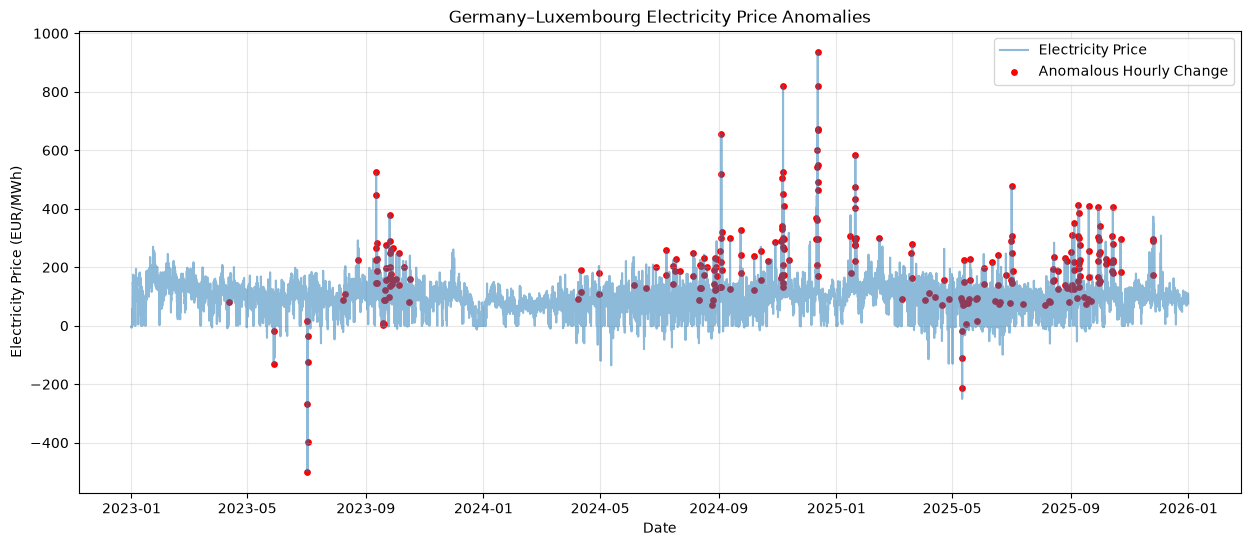

In [16]:
plt.figure(figsize=(15, 6))

plt.plot(
    df.index,
    df["price_eur_mwh"],
    label="Electricity Price",
    alpha=0.5
)

anomalies = df[df["is_anomaly"]]

plt.scatter(
    anomalies.index,
    anomalies["price_eur_mwh"],
    color="red",
    s=15,
    label="Anomalous Hourly Change"
)

plt.title("Germany–Luxembourg Electricity Price Anomalies")
plt.xlabel("Date")
plt.ylabel("Electricity Price (EUR/MWh)")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

2023: A notable cluster of extreme negative prices around July, with additional sharp movements in September.



2024: The largest positive price spikes, particularly toward November and December, including prices above €900/MWh.



2025: More frequent flagged price movements, including several clusters during the second half of the year.



Overall: The market experienced both extreme price levels and rapid hourly changes.

## Save processed dataset

In [17]:
from pathlib import Path

output_dir = Path("../data/processed")
output_dir.mkdir(parents=True, exist_ok=True)

df.to_parquet(
    output_dir / "germany_luxembourg_analytics.parquet",
    index=True
)

print("Analytics dataset saved successfully!")

Analytics dataset saved successfully!
